# MViTv2 training and evaluation
Fine-tunes MViTv2-S (torchvision, pretrained on Kinetics-400) as the comparison model for
CNNsa-BiLSTM, following the baseline of *Word-Level BISINDO: A Novel Video Indonesian Sign
Language Dataset and Baseline Methods*.

MViTv2 reads RGB clips (16 frames, 224x224) directly from the PreProcessing output and does
not need FeatureExtraction.

## 1. Setup and data check

In [1]:
import sys
import torch
from pathlib import Path

# This notebook lives in <ROOT>/Training/MViTv2/
sys.path.insert(0, str(Path.cwd().parent.parent))

from Training.MViTv2.Config.mvit_config import verify_data_exists, create_output_dirs, TRAIN_CONFIG
from Training.Scripts.device_utils import get_device

verify_data_exists()
create_output_dirs()

device = get_device()

print(f"Batch size: {TRAIN_CONFIG['batch_size']}")

[MViTConfig] frame_manifest.json ditemukan.
[MViTConfig] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[MViTConfig] Frame Manifest: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Processed\frame_manifest.json
[MViTConfig] Checkpoint Dir: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\mvit_v2\checkpoints
[MViTConfig] Log Dir       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\mvit_v2\logs
[MViTConfig] Results Dir   : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\results (shared)
[Device] GPU terdeteksi : NVIDIA GeForce RTX 5060 (compute capability sm_120)
[Device] CUDA runtime   : 12.8 (build PyTorch)
Batch size: 4 (kecil karena VRAM terbatas + clip video besar)


## 2. Model summary
Shows how many parameters are fine-tuned; the rest keep their Kinetics-400 weights.

In [2]:
from Training.MViTv2.Models.mvit_v2 import build_mvit_v2
from Training.MViTv2.Config.mvit_config import MODEL_CONFIG

model = build_mvit_v2(
    num_classes=MODEL_CONFIG["num_classes"],
    freeze_until_block=MODEL_CONFIG["freeze_until_block"],
    pretrained=MODEL_CONFIG["pretrained"],
    dropout=MODEL_CONFIG["dropout"],
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")
print(f"Freeze until block   : {MODEL_CONFIG['freeze_until_block']} / 16")


Total parameters     : 34,254,752
Trainable parameters : 17,218,208 (50.3%)
Freeze until block   : 12 / 16


## 3. Training

> Much slower per epoch than CNNsa-BiLSTM. Mixed precision is enabled when a GPU is available.

In [3]:
from Training.MViTv2.Scripts.mvit_trainer import run_training

run_training()

[MViTConfig] frame_manifest.json ditemukan.
[Device] GPU terdeteksi : NVIDIA GeForce RTX 5060 (compute capability sm_120)
[Device] CUDA runtime   : 12.8 (build PyTorch)
[MViTConfig] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[MViTConfig] Frame Manifest: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Processed\frame_manifest.json
[MViTConfig] Checkpoint Dir: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\mvit_v2\checkpoints
[MViTConfig] Log Dir       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\mvit_v2\logs
[MViTConfig] Results Dir   : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\results (shared)

[MViTTrainer] Loading datasets...
[MViTDataset] Train: 1120 video | Val: 224 video | Test: 256 video
  Train samples: 1120 (Batches: 280)
  Val samples  : 224 (Batches: 56)

[MViTTrainer] Initializing MViTv2 model...
  Trainable params: 17,218,208 / 34,254,752 (5

## 4. Evaluation
Evaluates the best checkpoint on the test split, which contains the same videos as the CNNsa-BiLSTM test split.

In [4]:
from Training.MViTv2.Scripts.mvit_evaluator import run_evaluation

# Writes transformer_evaluation_summary.json
run_evaluation()

[MViTConfig] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[MViTConfig] Frame Manifest: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Processed\frame_manifest.json
[MViTConfig] Checkpoint Dir: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\mvit_v2\checkpoints
[MViTConfig] Log Dir       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\mvit_v2\logs
[MViTConfig] Results Dir   : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\results (shared)

[MViTEvaluator] Loading test dataset...
[MViTDataset] Train: 1120 video | Val: 224 video | Test: 256 video
  Test samples: 256

[MViTEvaluator] Loading trained model on CPU...

[MViTEvaluator] Running evaluation over test set...

[MViTEvaluator] Hasil Evaluasi Akhir:
  Accuracy  : 99.22%
  F1-Score  : 99.22%
  Precision : 99.31%
  Recall    : 99.22%
  Confusion Matrix tersimpan ke: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_

## 5. Training curves

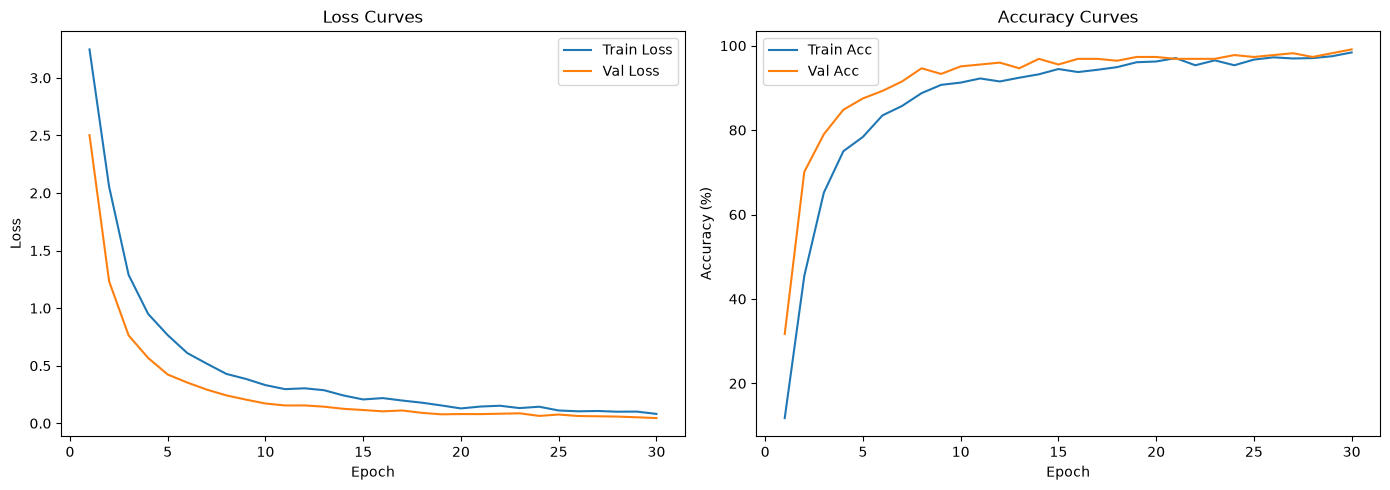

In [5]:
import json
import matplotlib.pyplot as plt
from Training.Config.shared_config import RESULTS_DIR

history_path = RESULTS_DIR / "mvit_v2_train_history.json"
if history_path.exists():
    with open(history_path, "r") as f:
        history = json.load(f)

    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.title("Loss Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, [x*100 for x in history["train_acc"]], label="Train Acc")
    plt.plot(epochs, [x*100 for x in history["val_acc"]], label="Val Acc")
    plt.title("Accuracy Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("No training history yet. Run the training cell first.")

## 6. Confusion matrix

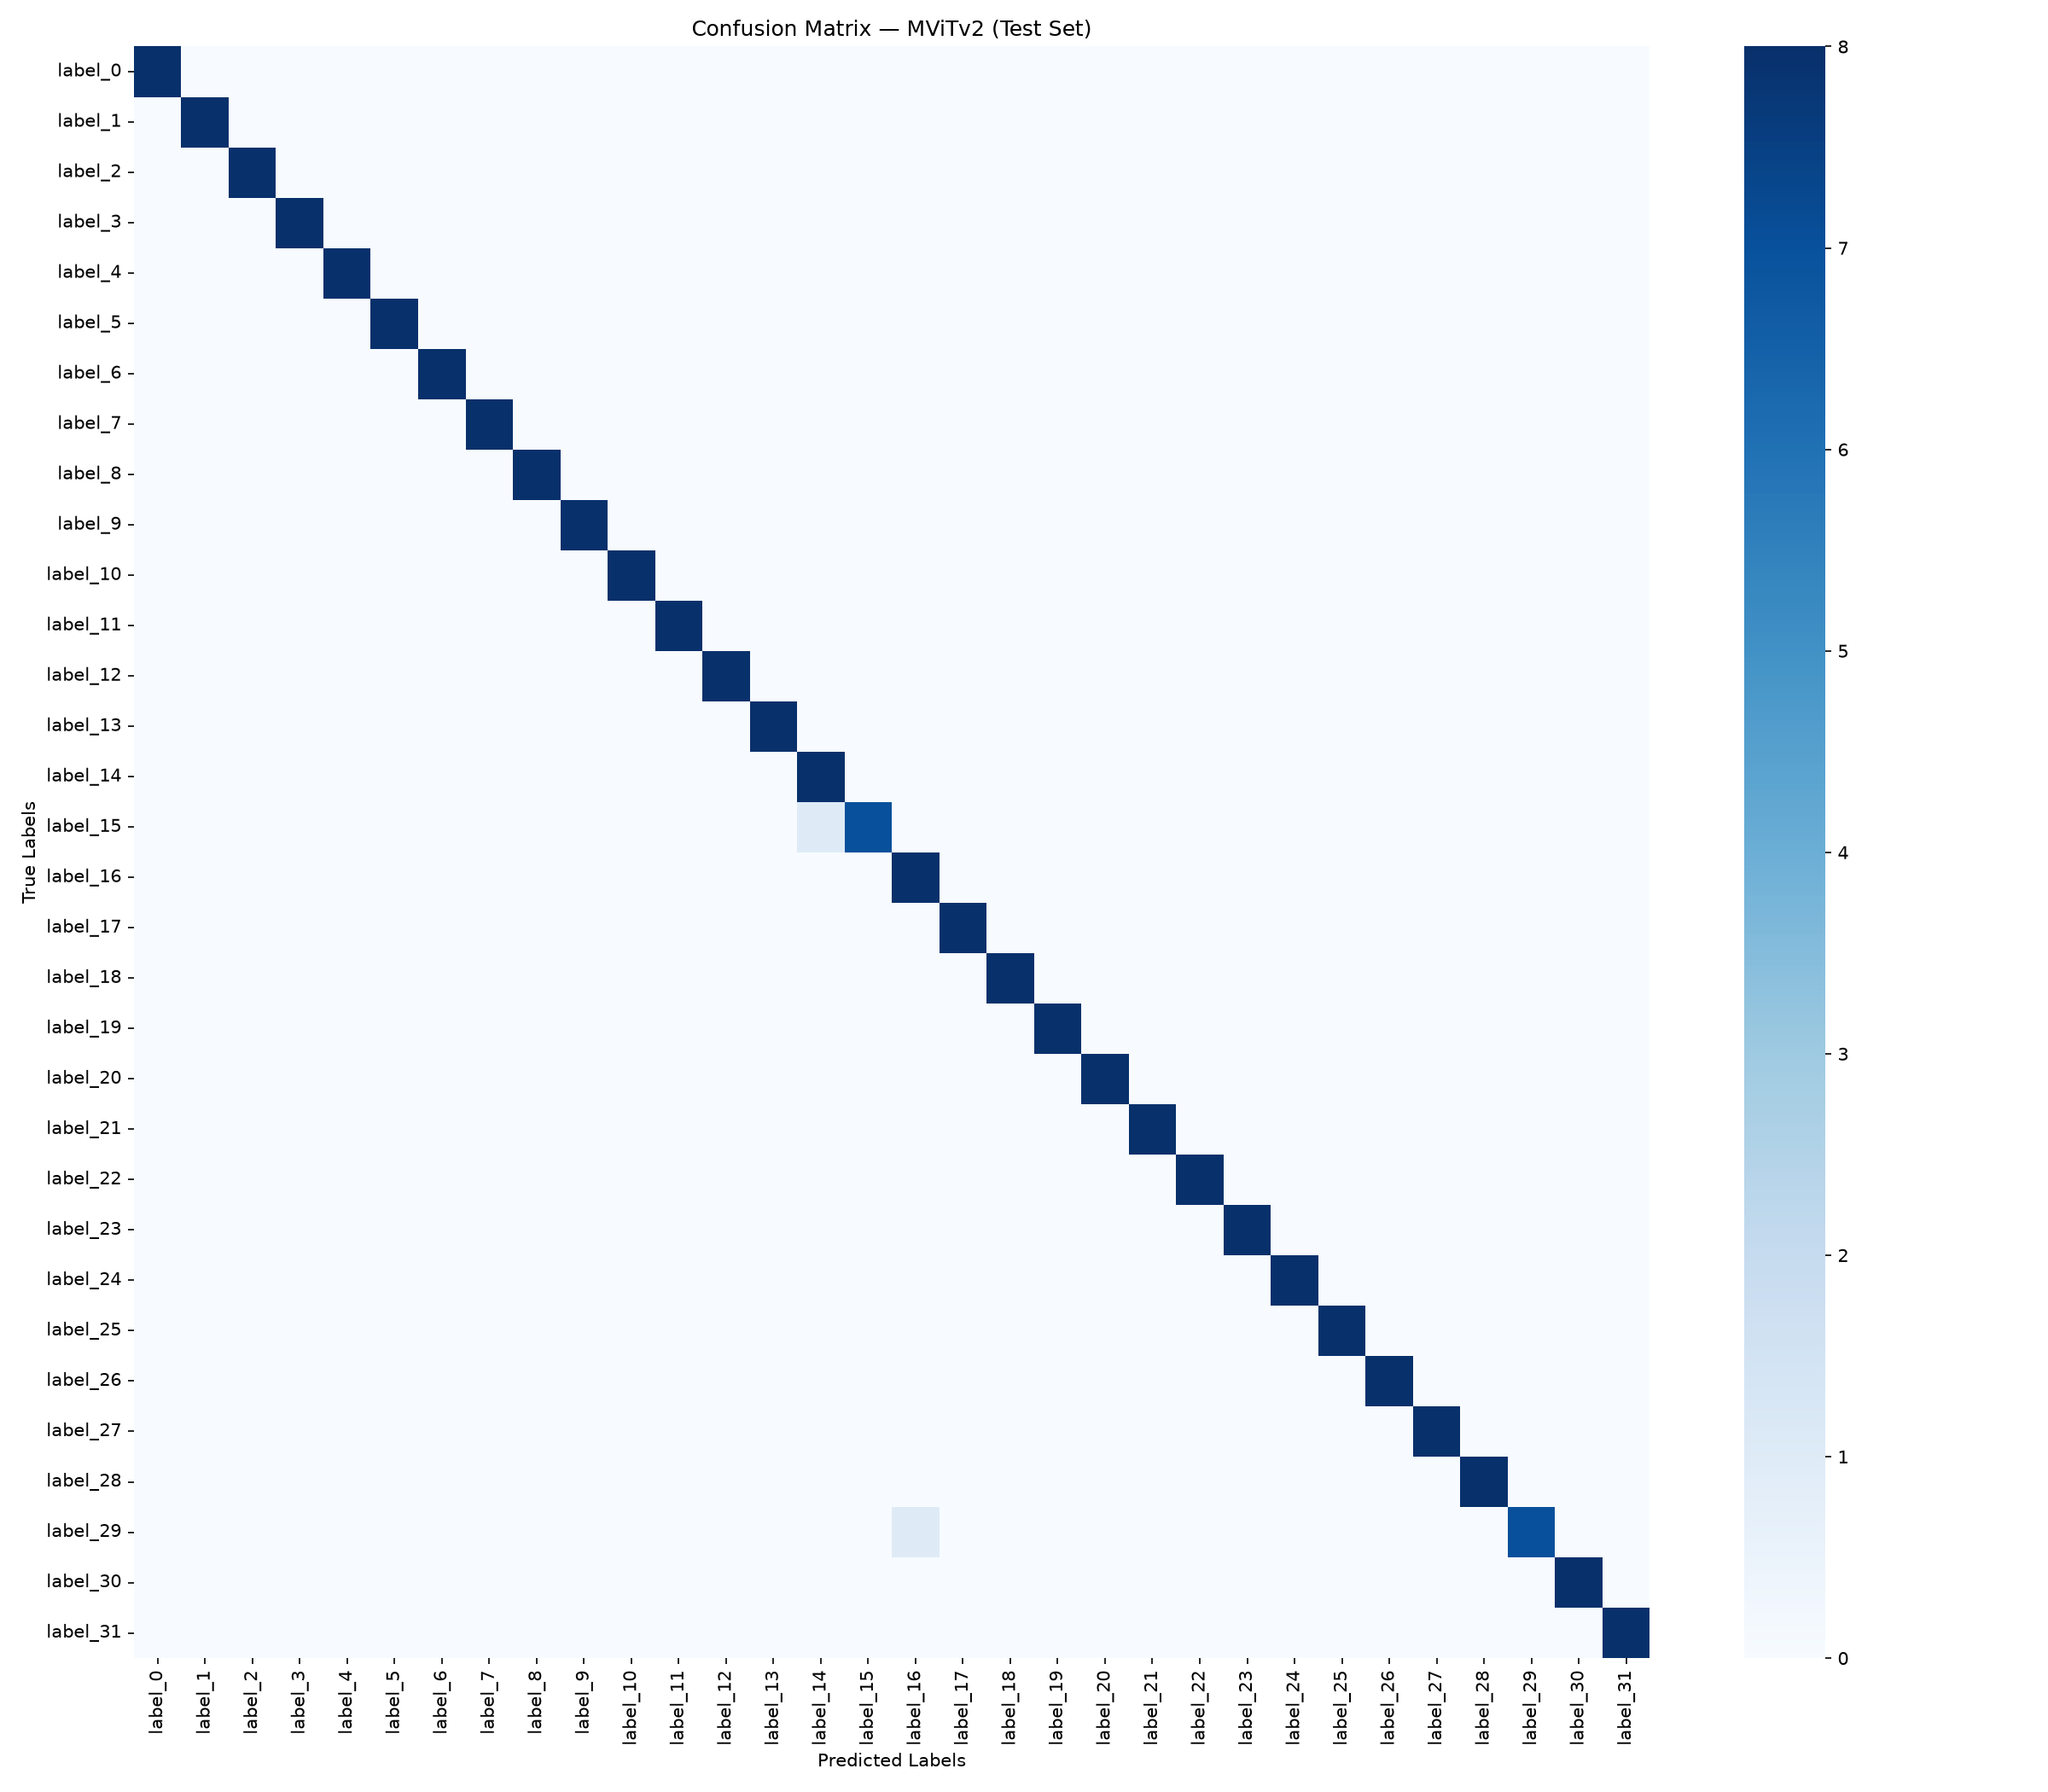

In [6]:
from IPython.display import Image, display
from Training.Config.shared_config import RESULTS_DIR

cm_path = RESULTS_DIR / "confusion_matrix_mvit_v2.png"
if cm_path.exists():
    display(Image(filename=str(cm_path)))
else:
    print("Confusion matrix image not found. Run the evaluation cell first.")

## 7. Comparison with CNNsa-BiLSTM
Run after `Training/CNNsaBiLSTM/Train.ipynb` has been evaluated, so that its
`evaluation_summary.json` exists.

In [7]:
from Training.Scripts.comparator import compare_models

compare_models()


[Comparator] Memulai perbandingan model...

=================== SUMMARY: CNNsa-BiLSTM (Proposed) ===================
  Accuracy           : 94.53%
  F1-Score (Weighted): 94.51%
  Inference (CPU)    : 3.24 ms/sequence
  Model Size         : 43.94 MB
  Total Parameters   : 3,835,808

=================== SUMMARY: MViTv2 (Baseline) ===================
  Accuracy           : 99.22%
  F1-Score (Weighted): 99.22%
  Inference (CPU)    : 400.07 ms/sequence
  Model Size         : 262.26 MB
  Total Parameters   : 34,254,752

=== Tabel Perbandingan Akhir ===
Metrik                    | CNNsa-BiLSTM (Proposed)   | MViTv2 (Baseline)        
---------------------------------------------------------------------------------
accuracy                  |                   94.53% |                   99.22%
f1_weighted               |                   94.51% |                   99.22%
avg_inference_cpu_ms      |                 3.24 ms |               400.07 ms
model_size_mb             |                 4